**1.Preparación del entorno**

Objetivo: instalar e importar las herramientas necesarias. Ejecutar primero.


In [1]:
%pip -q install earthengine-api folium pandas numpy matplotlib seaborn requests

import ee
import folium
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import base64
import calendar

from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display, FileLink

**2.Configuración — único bloque editable**

Objetivo: definir el experimento sin modificar las celdas de procesamiento.

Se conservan los valores principales del cuaderno original. Los límites GAUL de 2015 también se conservan; el archivo original ya muestra una advertencia de obsolescencia, por lo que no se sustituyen automáticamente por otra versión sin verificar su esquema.

In [2]:
# CONEXIÓN Y ÁREA DE ESTUDIO
EE_PROJECT = "gee-ecuador"
ADMIN1_ASSET = "FAO/GAUL/2015/level1"
ADMIN2_ASSET = "FAO/GAUL/2015/level2"
COUNTRY = "Ecuador"
PROVINCE = "Guayas"

# PERÍODOS
start_year, end_year = 2020, 2025
YEAR_TO_ANALYZE = 2024
RUN_ANNUAL = True
RUN_MONTHLY = True

# RESOLUCIÓN DE CÁLCULO
scale_m = 7000

# CONTAMINANTE: MISMA BANDA PARA ANÁLISIS ANUAL Y MENSUAL
POLLUTANTS = [
    {
        "S5P_COLLECTION": "COPERNICUS/S5P/OFFL/L3_NO2",
        "POLLUTANT_BAND": "tropospheric_NO2_column_number_density",
        "POLLUTANT_NAME": "NO2",
        "POLLUTANT_UNIT": "mol/m²",
    },
]

# ESTADÍSTICOS TEMPORALES Y ESPACIALES
# Se conserva la lógica original:
# primero se calcula el estadístico temporal por píxel;
# después, el mismo estadístico espacial por cantón.
STAT_TASKS = [
    {"STAT_MODE": "median", "PERCENTILE_Q": None},
    {"STAT_MODE": "percentile", "PERCENTILE_Q": 90},
    {"STAT_MODE": "percentile", "PERCENTILE_Q": 95},
    {"STAT_MODE": "percentile", "PERCENTILE_Q": 99},
]

# FILTRO MENSUAL: SOLO PARA EL COMPUESTO ANUAL
APPLY_MONTH_STD_FILTER = True
MONTH_FILTER_K = 2.0
MONTH_FILTER_MIN_MONTHS = 9
MONTH_FILTER_REF_COMPOSITE = "median"

# PRESENTACIÓN Y EXPORTACIÓN
DOWNLOAD_MODE = "raster"  # "raster" o "canton"
DOWNLOAD_MAPS = True
EXPORT_HTML = True
ADD_BORDERS = True
DIMENSIONS = 240
TOP_N = 10
palette = ["navy", "blue", "cyan", "green", "yellow", "orange", "red"]

# ARCHIVOS Y MAPA
OUTPUT_DIR = "resultados_sentinel5p"
HTML_FILENAME = "mapa_anual_guayas.html"
MAP_CENTER = [-2.2, -79.9]
MAP_ZOOM = 8

# EXTENSIONES OPCIONALES DEL CUADERNO ORIGINAL
POP_FILE = "poblacion.csv"
metric_for_ml = "p99"
K_MIN, K_MAX = 2, 7
K_FINAL = 3
RANDOM_STATE = 42
N_INIT = 20

# VALIDACIÓN LOCAL: NO CONSULTA EARTH ENGINE
assert start_year <= end_year
assert scale_m > 0
assert DOWNLOAD_MODE in ("raster", "canton")
assert MONTH_FILTER_REF_COMPOSITE == "median"
assert 1 <= MONTH_FILTER_MIN_MONTHS <= 12
assert MONTH_FILTER_K > 0
assert POLLUTANTS and STAT_TASKS

for task in STAT_TASKS:
    assert task["STAT_MODE"] in ("median", "percentile")
    if task["STAT_MODE"] == "percentile":
        assert task["PERCENTILE_Q"] in (90, 95, 99)

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(exist_ok=True)

print("Configuración validada.")
print("NO₂ troposférico para ambos análisis.")

Configuración validada.
NO₂ troposférico para ambos análisis.


**3.Conexión con Earth Engine**

Objetivo: autenticar la sesión y comprobar el acceso al proyecto.

In [3]:
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)

print(ee.String("Conexión con Earth Engine establecida.").getInfo())

Conexión con Earth Engine establecida.


**4.Área de estudio**

Objetivo: cargar la provincia y los cantones antes de consultar el contaminante.

In [4]:
guayas_fc = (
    ee.FeatureCollection(ADMIN1_ASSET)
    .filter(ee.Filter.eq("ADM0_NAME", COUNTRY))
    .filter(ee.Filter.eq("ADM1_NAME", PROVINCE))
)

cantones_guayas = (
    ee.FeatureCollection(ADMIN2_ASSET)
    .filter(ee.Filter.eq("ADM0_NAME", COUNTRY))
    .filter(ee.Filter.eq("ADM1_NAME", PROVINCE))
)

n_provincias = guayas_fc.size().getInfo()
n_cantones = cantones_guayas.size().getInfo()

if not n_provincias or not n_cantones:
    raise RuntimeError("No se encontró la provincia o sus cantones.")

bounds = guayas_fc.geometry().dissolve()
CANTON_NAMES = cantones_guayas.aggregate_array("ADM2_NAME").getInfo()

# Earth Engine devuelve [longitud, latitud].
extent_ring = bounds.bounds().coordinates().getInfo()[0]
longitudes, latitudes = zip(*extent_ring)
MAP_BOUNDS = [
    [min(latitudes), min(longitudes)],
    [max(latitudes), max(longitudes)],
]

print("Elementos provinciales:", n_provincias)
print("Cantones:", n_cantones)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Elementos provinciales: 1
Cantones: 25


**5.Funciones estadísticas compartidas**

Objetivo: reutilizar exactamente la misma lógica para los períodos anuales y mensuales.

In [5]:
def stat_label(task):
    if task["STAT_MODE"] == "median":
        return "median"
    return f'p{int(task["PERCENTILE_Q"])}'


def build_reducer(task):
    if task["STAT_MODE"] == "median":
        return ee.Reducer.median().setOutputs(["pollutant_stat"])
    return ee.Reducer.percentile(
        [int(task["PERCENTILE_Q"])]
    ).setOutputs(["pollutant_stat"])


def stat_image(collection, task):
    median = collection.median().rename("pollutant_stat")
    if task["STAT_MODE"] == "median":
        return median
    percentile = collection.reduce(
        ee.Reducer.percentile([int(task["PERCENTILE_Q"])])
    ).rename("pollutant_stat")
    return percentile.unmask(median)


def load_collection(cfg, first_year, last_year):
    return (
        ee.ImageCollection(cfg["S5P_COLLECTION"])
        .filterBounds(bounds)
        .filterDate(f"{first_year}-01-01", f"{last_year + 1}-01-01")
        .select(cfg["POLLUTANT_BAND"])
    )


def reduce_cantons(image, task):
    return image.reduceRegions(
        collection=cantones_guayas,
        reducer=build_reducer(task),
        scale=scale_m,
        tileScale=4,
    )


def image_for_map(image, task):
    if DOWNLOAD_MODE == "raster":
        return image.clip(bounds)

    features = reduce_cantons(image, task).filter(
        ee.Filter.notNull(["pollutant_stat"])
    )
    return features.reduceToImage(
        properties=["pollutant_stat"],
        reducer=ee.Reducer.first(),
    ).rename("pollutant_stat").clip(bounds)


def table_rows(image, task, period, n_raw, n_used):
    if image is None:
        return [
            dict(canton=name, **period, n_images=n_raw,
                 n_images_used=n_used, value=None)
            for name in CANTON_NAMES
        ]

    # No se descargan geometrías para construir la tabla.
    features = reduce_cantons(image, task).map(
        lambda feature: ee.Feature(None, {
            "canton": feature.get("ADM2_NAME"),
            "value": feature.get("pollutant_stat"),
        })
    ).getInfo()["features"]

    return [
        dict(
            canton=feature["properties"].get("canton"),
            **period,
            n_images=n_raw,
            n_images_used=n_used,
            value=feature["properties"].get("value"),
        )
        for feature in features
    ]

**6.Filtro mensual para los compuestos anuales**

Objetivo: identificar meses atípicos a partir del promedio provincial de la mediana mensual.

El filtro descarta meses completos, no observaciones individuales. Por ello, conviene comparar en clase los resultados con el filtro activado y desactivado: un mes extremo también puede representar un episodio real.

In [6]:
def compute_months_keep(collection, cfg, year):
    available, values = [], []

    for month in range(1, 13):
        start = ee.Date.fromYMD(year, month, 1)
        monthly = collection.filterDate(start, start.advance(1, "month"))

        if monthly.size().getInfo() == 0:
            continue

        value = monthly.median().reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=bounds,
            scale=scale_m,
            maxPixels=1e13,
            bestEffort=True,
            tileScale=4,
        ).get(cfg["POLLUTANT_BAND"]).getInfo()

        if value is not None and np.isfinite(value):
            available.append(month)
            values.append(float(value))

    median = float(np.median(values)) if values else None
    std = float(np.std(values)) if values else None
    keep = available.copy()
    fallback = False

    if len(values) >= 2 and std > 0:
        keep = [
            month for month, value in zip(available, values)
            if abs(value - median) <= MONTH_FILTER_K * std
        ]

        # Regla de respaldo conservada del cuaderno original.
        if (
            len(keep) < MONTH_FILTER_MIN_MONTHS
            and len(available) >= MONTH_FILTER_MIN_MONTHS
        ):
            keep = available.copy()
            fallback = True

    return {
        "months_avail": available,
        "months_keep": keep,
        "median": median,
        "std": std,
        "fallback": fallback,
    }


def apply_month_filter(collection, months_keep):
    # Respaldo original: si no hay meses seleccionados, no filtrar.
    if not months_keep:
        return collection

    with_month = collection.map(
        lambda image: image.set(
            "month",
            ee.Date(image.get("system:time_start")).get("month")
        )
    )
    return with_month.filter(ee.Filter.inList("month", months_keep))

**7.Procesamiento anual y CSV**

Objetivo: generar las imágenes anuales una sola vez y conservarlas para los gráficos, PNG y HTML.

n_images representa las imágenes antes del filtro y n_images_used, las utilizadas después del filtro. Estos conteos no equivalen al número de observaciones válidas de cada píxel.

In [7]:
annual_results = {}
filter_diagnostics = []

if RUN_ANNUAL:
    for cfg in POLLUTANTS:
        collection = load_collection(cfg, start_year, end_year)
        yearly_collections = {}

        for year in range(start_year, end_year + 1):
            raw = collection.filterDate(
                f"{year}-01-01", f"{year + 1}-01-01"
            )
            n_raw = raw.size().getInfo()
            used = raw

            if APPLY_MONTH_STD_FILTER and n_raw:
                diagnostic = compute_months_keep(raw, cfg, year)
                used = apply_month_filter(raw, diagnostic["months_keep"])
                if used.size().getInfo() == 0:
                    used = raw

                filter_diagnostics.append({
                    "pollutant": cfg["POLLUTANT_NAME"],
                    "year": year,
                    **diagnostic,
                })

            n_used = used.size().getInfo() if n_raw else 0
            yearly_collections[year] = (used, n_raw, n_used)
            print(cfg["POLLUTANT_NAME"], year, "imágenes:", n_used)

        for task in STAT_TASKS:
            label = stat_label(task)
            images, rows = {}, []

            for year, (used, n_raw, n_used) in yearly_collections.items():
                image = stat_image(used, task).clip(bounds) if n_used else None

                if image is not None:
                    images[year] = image

                rows.extend(table_rows(
                    image, task, {"year": year}, n_raw, n_used
                ))

            value_col = (
                f'{cfg["POLLUTANT_NAME"]}_{label}_{cfg["POLLUTANT_UNIT"]}'
            )
            df = pd.DataFrame(rows).rename(columns={"value": value_col})
            df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
            df = df.sort_values(["canton", "year"]).reset_index(drop=True)

            filename = (
                f'{cfg["POLLUTANT_NAME"].lower()}_cantones_guayas_'
                f'{start_year}_{end_year}_{label}.csv'
            )
            df.to_csv(output_dir / filename, index=False)

            annual_results[(cfg["POLLUTANT_NAME"], label)] = {
                "cfg": cfg,
                "task": task,
                "df": df,
                "value_col": value_col,
                "images": images,
            }

    if filter_diagnostics:
        diagnostics_df = pd.DataFrame(filter_diagnostics)
        diagnostics_df.to_csv(
            output_dir / "diagnostico_filtro_mensual.csv", index=False
        )
        display(diagnostics_df)

NO2 2020 imágenes: 5178
NO2 2021 imágenes: 5168
NO2 2022 imágenes: 5152
NO2 2023 imágenes: 5077
NO2 2024 imágenes: 5164
NO2 2025 imágenes: 4591


,pollutant,year,months_avail,months_keep,median,std,fallback
0,NO2,2020,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",0.000018,0.000005,False
1,NO2,2021,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",0.000022,0.000005,False
2,NO2,2022,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",0.000023,0.000005,False
3,NO2,2023,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",0.000021,0.000003,False
4,NO2,2024,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",0.000023,0.000006,False
5,NO2,2025,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",0.000023,0.000006,False


**8.Gráficos para interpretar los resultados**

Objetivo: comparar evolución, distribución y patrones entre cantones.

La línea negra es el promedio simple de los valores cantonales; no es un promedio provincial ponderado por superficie o población.

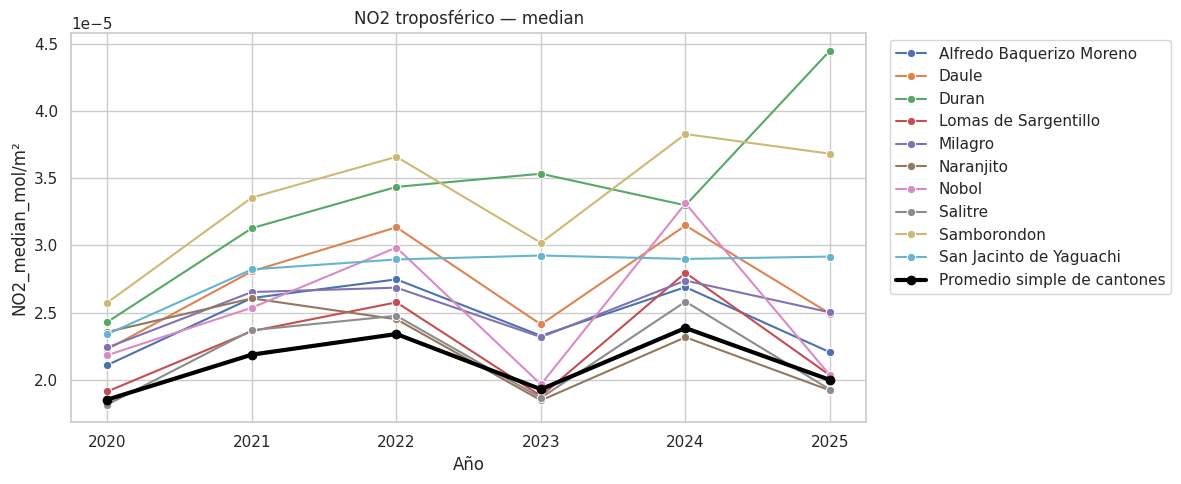

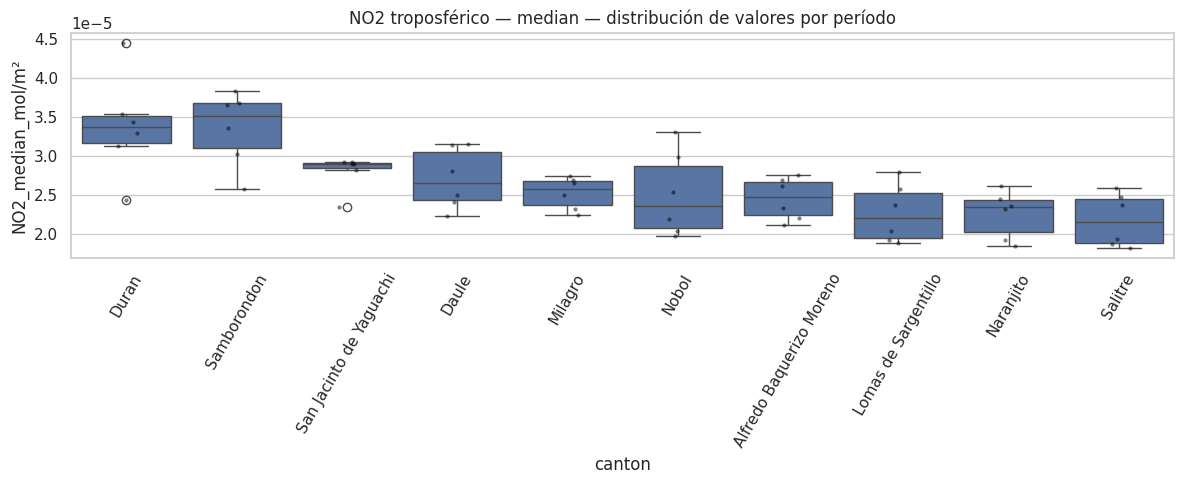

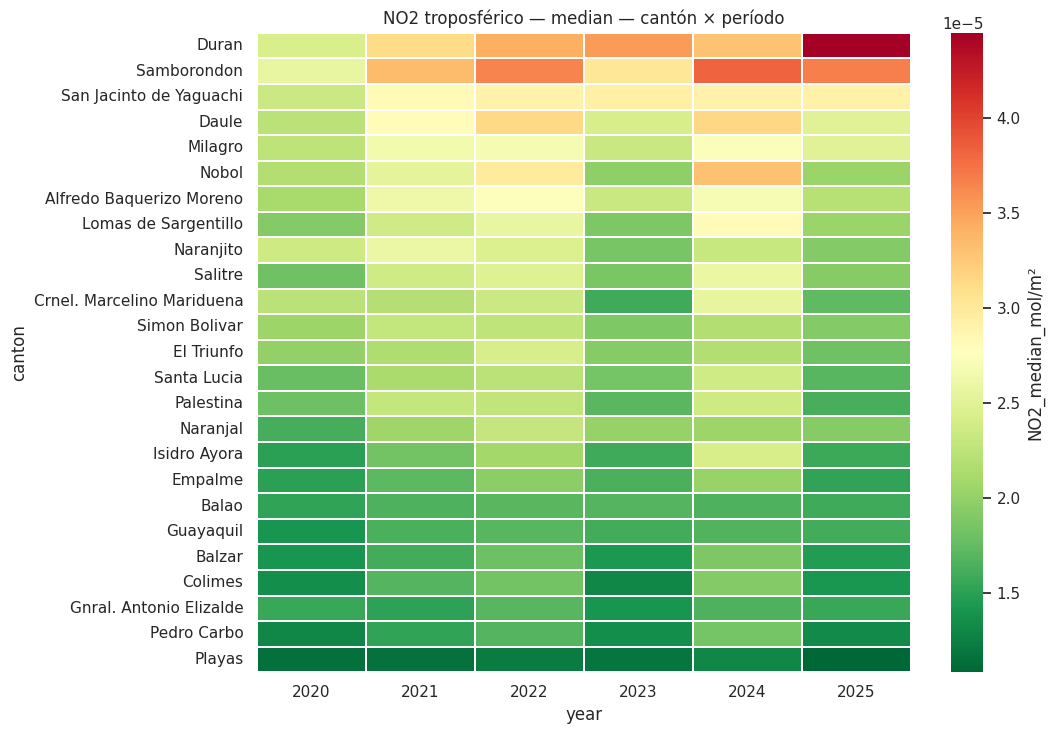

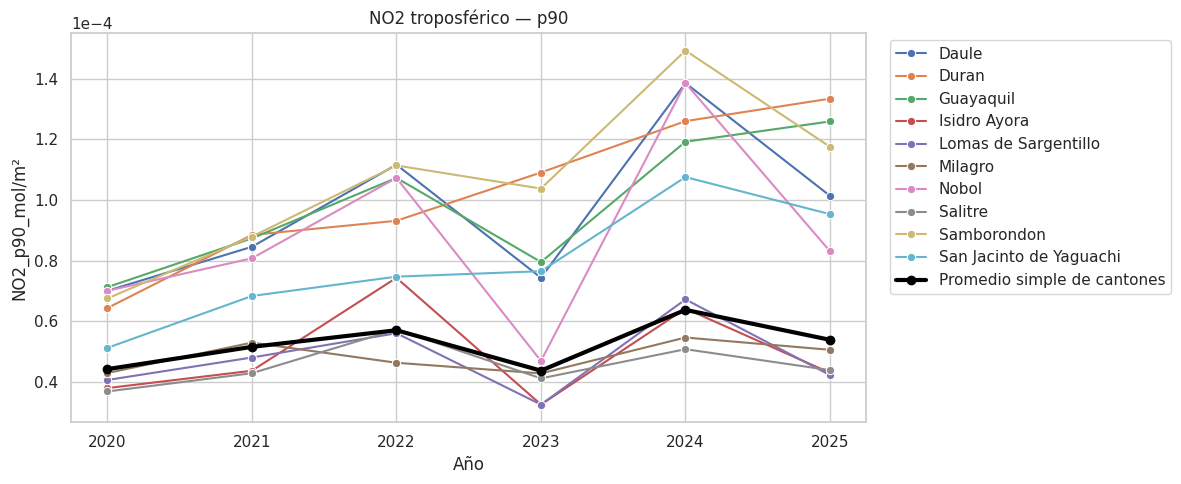

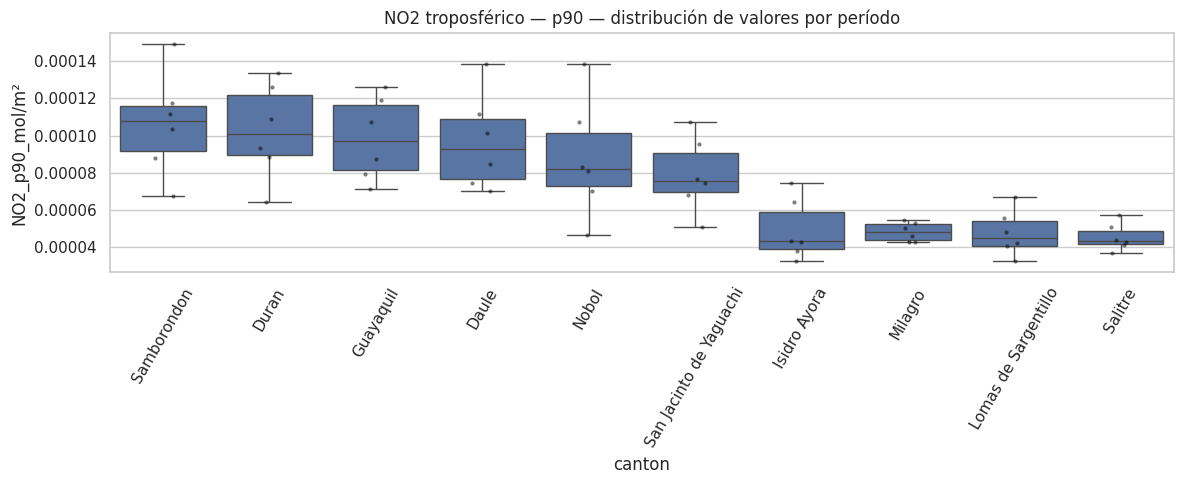

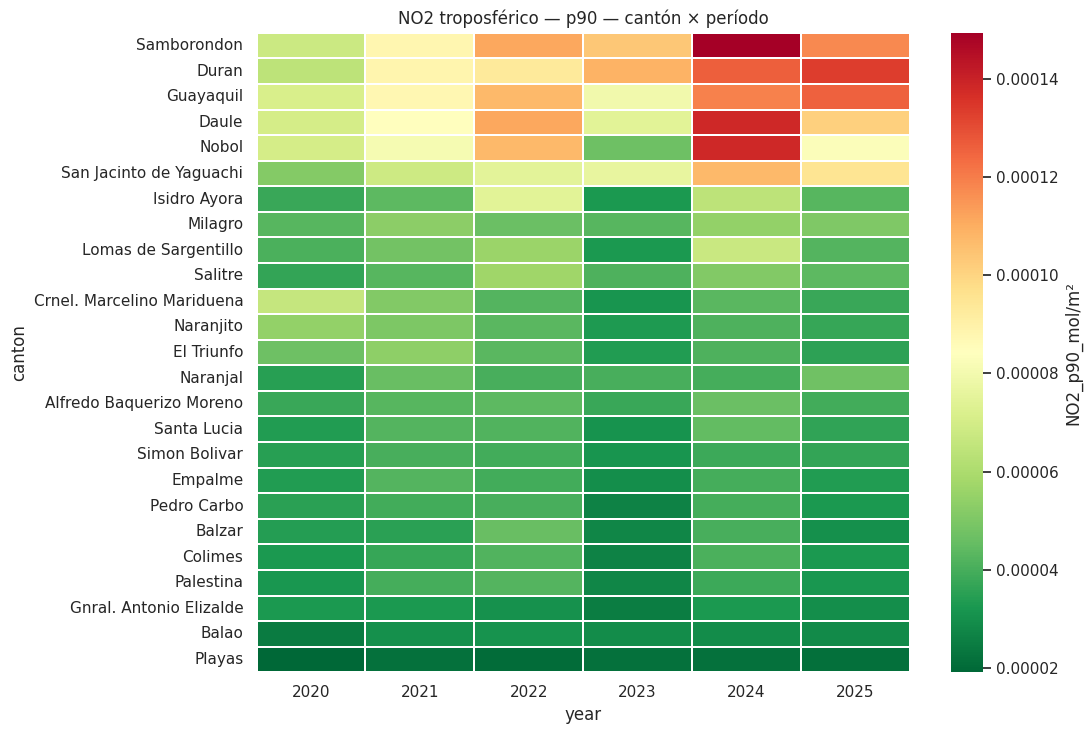

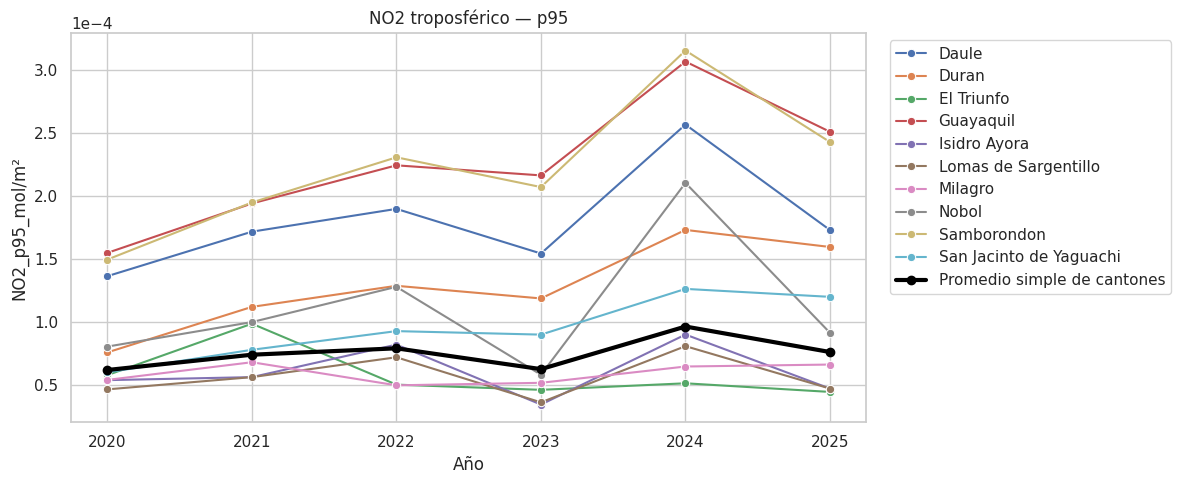

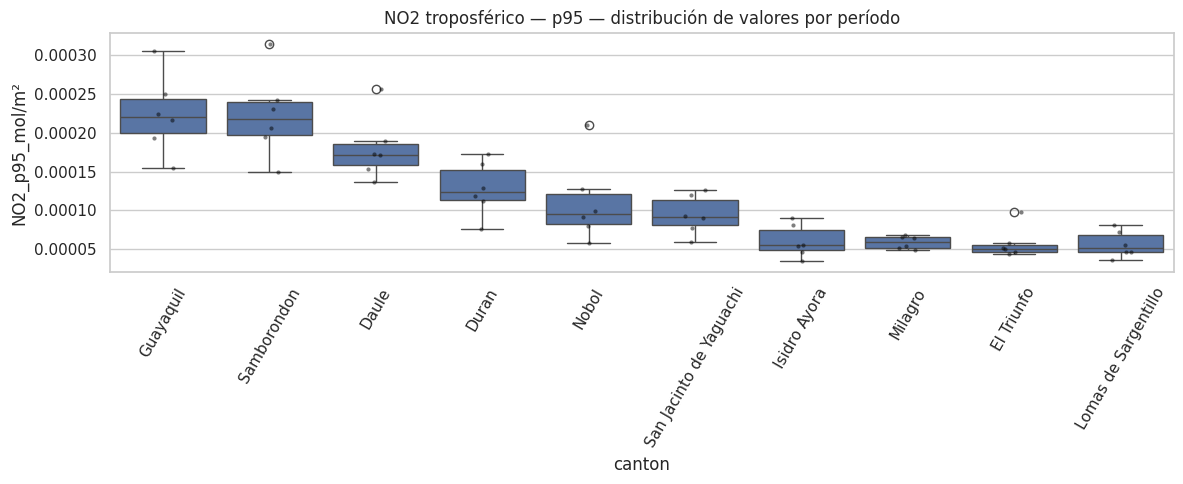

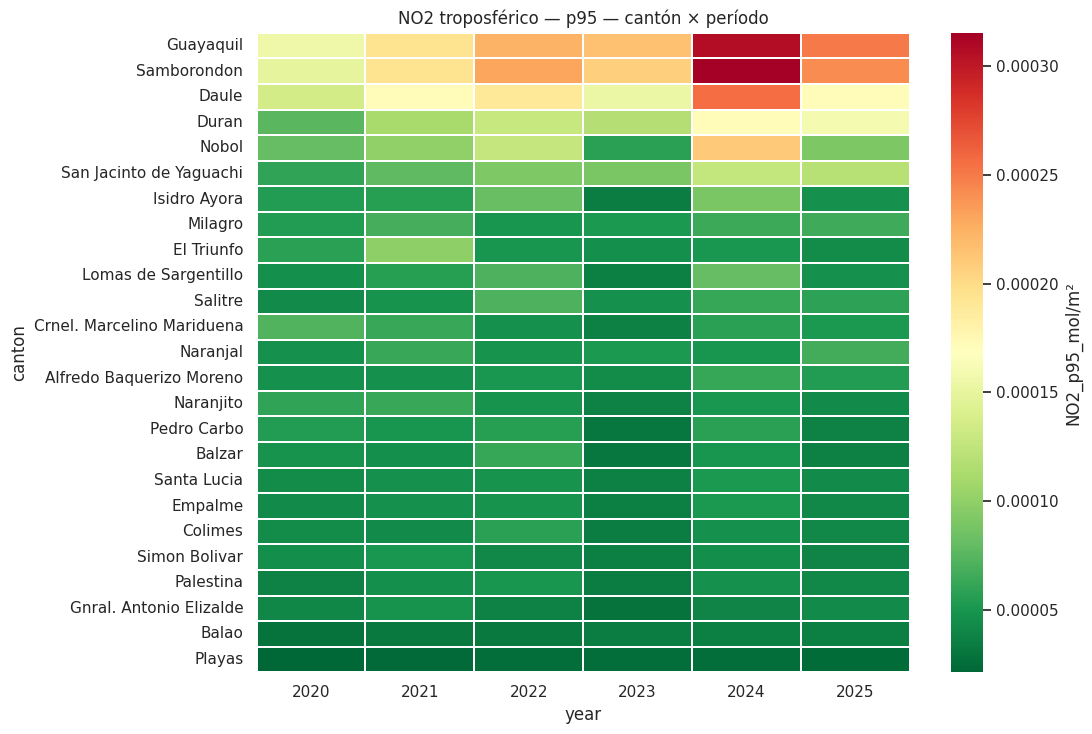

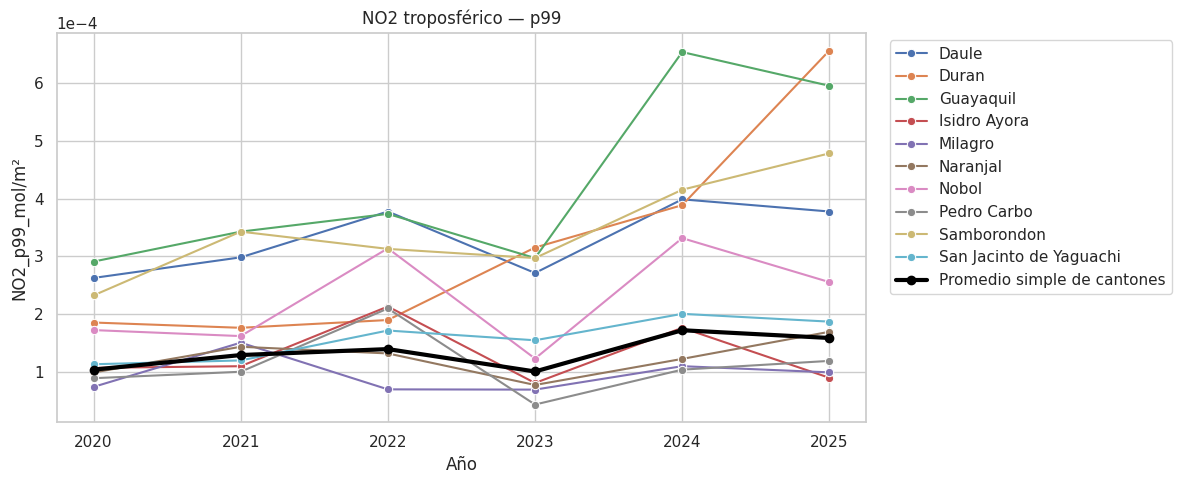

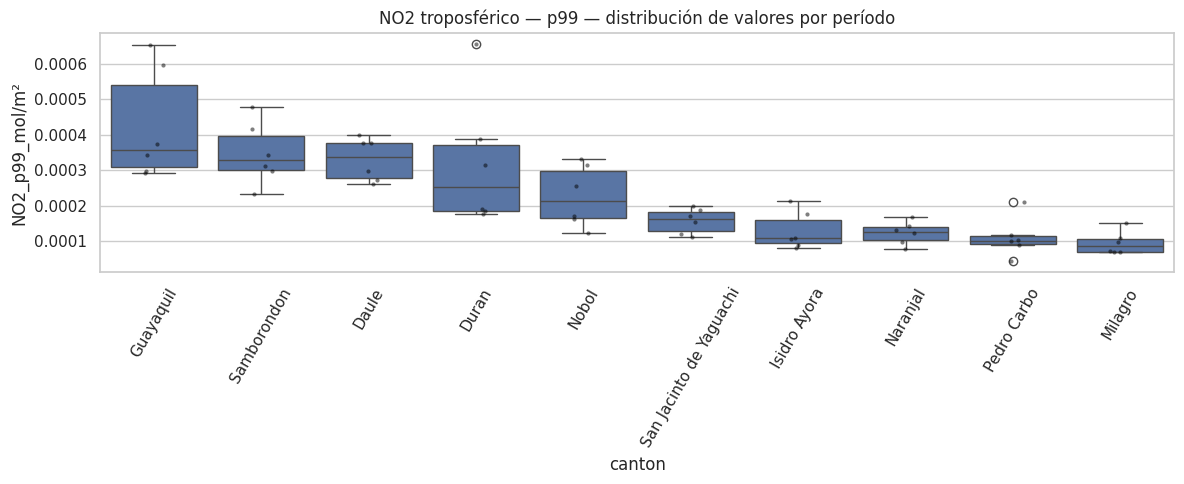

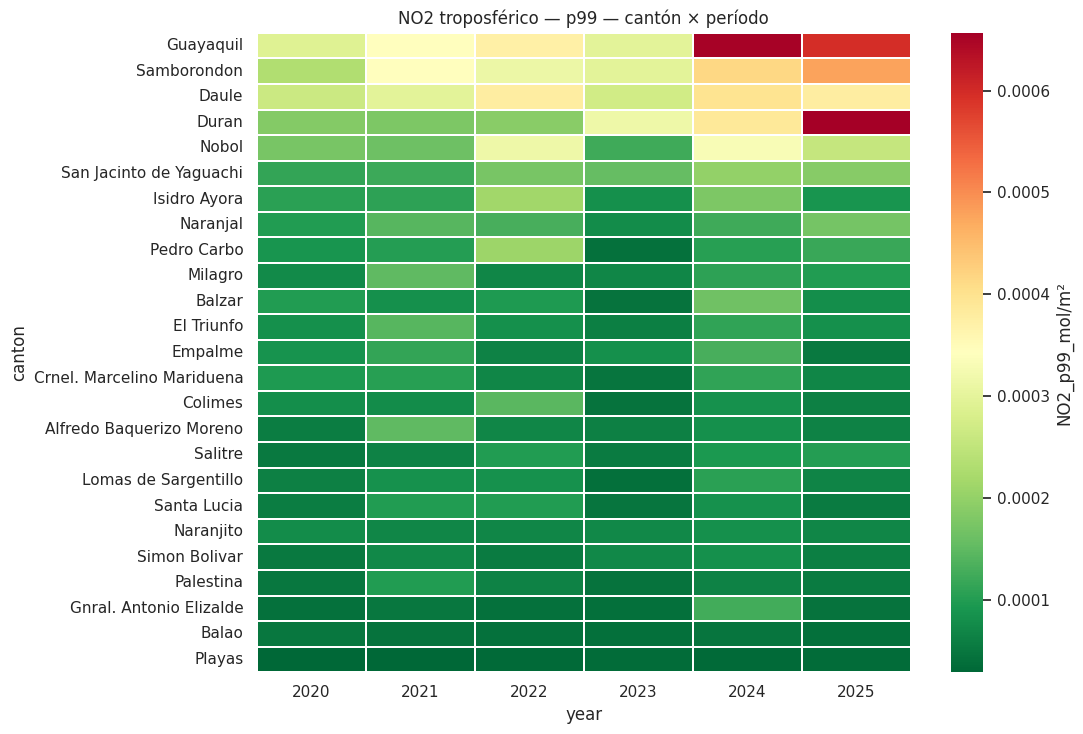

In [8]:
def plot_results(result, time_col, title):
    df = result["df"]
    value_col = result["value_col"]
    valid = df.dropna(subset=[value_col]).copy()

    if valid.empty:
        print("Sin valores válidos:", title)
        return

    order = (
        valid.groupby("canton")[value_col]
        .mean().sort_values(ascending=False).head(TOP_N).index
    )
    top = valid[valid["canton"].isin(order)]
    sns.set_theme(style="whitegrid")

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.lineplot(
        data=top, x=time_col, y=value_col,
        hue="canton", marker="o", ax=ax
    )
    average = valid.groupby(time_col, as_index=False)[value_col].mean()
    ax.plot(
        average[time_col], average[value_col],
        color="black", linewidth=3, marker="o",
        label="Promedio simple de cantones"
    )
    ax.set_title(title)
    ax.set_ylabel(value_col)
    ax.set_xlabel("Año" if time_col == "year" else "Mes")
    ax.set_xticks(sorted(df[time_col].unique()))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.boxplot(data=top, x="canton", y=value_col, order=order, ax=ax)
    sns.stripplot(
        data=top, x="canton", y=value_col, order=order,
        color="black", alpha=0.5, size=3, ax=ax
    )
    ax.set_title(title + " — distribución de valores por período")
    ax.tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.show()

    pivot = df.pivot(index="canton", columns=time_col, values=value_col)
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(11, max(6, len(pivot) * 0.3)))
    sns.heatmap(
        pivot, cmap="RdYlGn_r", linewidths=0.25,
        cbar_kws={"label": value_col}, ax=ax
    )
    ax.set_title(title + " — cantón × período")
    plt.tight_layout()
    plt.show()


for (pollutant, label), result in annual_results.items():
    plot_results(result, "year", f"{pollutant} troposférico — {label}")

**9.Escala común y preparación de los mapas**

Objetivo: impedir que cada año cambie su escala de colores.

Se mantiene el criterio anual original: percentiles espaciales 2 y 98 de la mediana de los compuestos anuales. Los valores fuera del intervalo quedan saturados en los extremos de la paleta.

In [9]:
def common_limits(images, percentiles=True):
    representative = ee.ImageCollection.fromImages(
        list(images.values())
    ).median().rename("pollutant_stat")

    if percentiles:
        limits = representative.reduceRegion(
            reducer=ee.Reducer.percentile([2, 98]),
            geometry=bounds,
            scale=scale_m,
            maxPixels=1e13,
            bestEffort=True,
        ).getInfo()
        low = limits.get("pollutant_stat_p2")
        high = limits.get("pollutant_stat_p98")
    else:
        low, high = None, None

    if low is None or high is None:
        limits = representative.reduceRegion(
            reducer=ee.Reducer.minMax(),
            geometry=bounds,
            scale=scale_m,
            maxPixels=1e13,
            bestEffort=True,
        ).getInfo()
        low = limits.get("pollutant_stat_min")
        high = limits.get("pollutant_stat_max")

    if low is None or high is None:
        raise RuntimeError("No se pudo calcular una escala con datos válidos.")

    return float(low), max(float(high), float(low) + 1e-12)


def render_png(image, low, high):
    rgb = image.visualize(min=low, max=high, palette=palette)

    if ADD_BORDERS:
        for features, width in [(cantones_guayas, 1), (guayas_fc, 2)]:
            border = ee.Image().byte().paint(
                features, 1, width
            ).visualize(palette=["000000"])
            rgb = rgb.blend(border)

    url = rgb.getThumbURL({
        "region": bounds.bounds(),
        "dimensions": DIMENSIONS,
        "format": "png",
        "crs": "EPSG:4326",
    })
    response = requests.get(url, timeout=1200)
    response.raise_for_status()
    return response.content


def save_legend(result, low, high, filename):
    cmap = LinearSegmentedColormap.from_list("contaminante", palette)
    fig, ax = plt.subplots(figsize=(7, 1.5))
    fig.colorbar(
        ScalarMappable(norm=Normalize(low, high), cmap=cmap),
        cax=ax, orientation="horizontal",
        label=f'{result["cfg"]["POLLUTANT_NAME"]} '
              f'({result["cfg"]["POLLUTANT_UNIT"]})'
    )
    fig.savefig(output_dir / filename, bbox_inches="tight")
    plt.close(fig)


for (pollutant, label), result in annual_results.items():
    if not result["images"]:
        continue

    map_images = {
        year: image_for_map(image, result["task"])
        for year, image in result["images"].items()
    }
    low, high = common_limits(map_images)
    result.update(map_images=map_images, vmin=low, vmax=high)

    print(pollutant, label, "escala común:", low, high)

    save_legend(
        result, low, high,
        f"{pollutant.lower()}_{label}_leyenda_anual.png"
    )

    # Los mismos bytes se usan en los PNG y en el HTML.
    result["png_by_year"] = {}
    if DOWNLOAD_MAPS or EXPORT_HTML:
        for year, image in map_images.items():
            png = render_png(image, low, high)
            result["png_by_year"][year] = png

            if DOWNLOAD_MAPS:
                filename = (
                    f"{pollutant.lower()}_{label}_{DOWNLOAD_MODE}_{year}.png"
                )
                (output_dir / filename).write_bytes(png)

NO2 median escala común: 1.159305929936034e-05 7.331493534534249e-05
NO2 p90 escala común: 2.0438902446357988e-05 0.00014920712511980975
NO2 p95 escala común: 2.2205821194858382e-05 0.00017822686775559543
NO2 p99 escala común: 2.7677839079552963e-05 0.000246486756239371


**10.Mapa interactivo anual y descarga del HTML**

Objetivo: abrir el mapa en el navegador y cambiar de año.

Se genera un HTML por contaminante y estadístico, para no mezclar escalas diferentes. En el control superior derecho se selecciona un año a la vez.

Las imágenes del contaminante están incorporadas en el HTML. El mapa de fondo y las librerías web de Folium requieren conexión a internet. Además, las imágenes son visualizaciones: no permiten consultar el valor numérico de cada píxel y su detalle está limitado por DIMENSIONS.


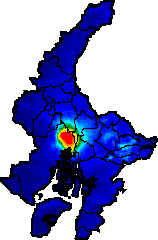
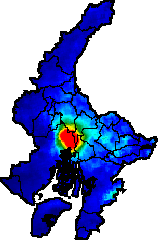
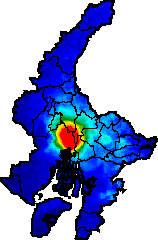
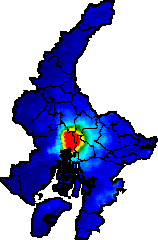
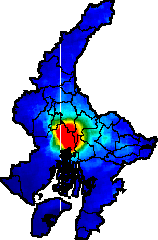
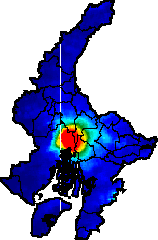

/content/resultados_sentinel5p/mapa_anual_guayas_no2_median.html


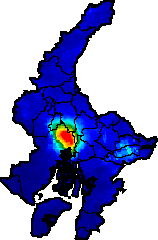
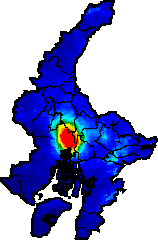
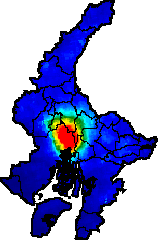
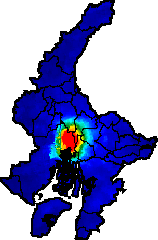
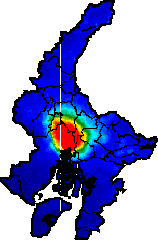
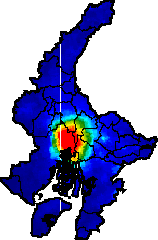

/content/resultados_sentinel5p/mapa_anual_guayas_no2_p90.html


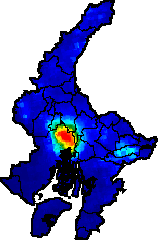
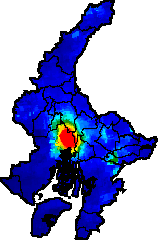
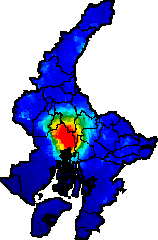
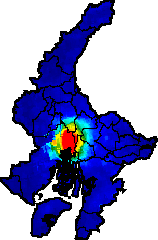
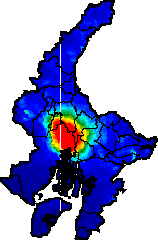
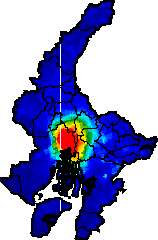

/content/resultados_sentinel5p/mapa_anual_guayas_no2_p95.html


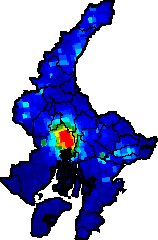
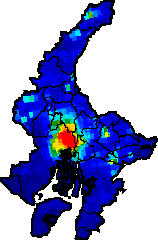
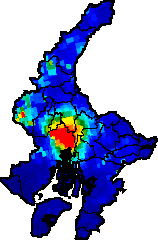
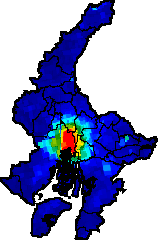
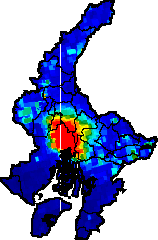
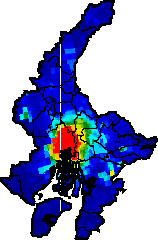

/content/resultados_sentinel5p/mapa_anual_guayas_no2_p99.html

/content/resultados_sentinel5p/mapas_html_anuales.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
html_files = []

if EXPORT_HTML:
    from html import escape

    for (pollutant, label), result in annual_results.items():
        png_by_year = result.get("png_by_year", {})
        if not png_by_year:
            continue

        annual_map = folium.Map(
            location=MAP_CENTER,
            zoom_start=MAP_ZOOM,
            tiles=None
        )

        # Fondo siempre activo; las capas base se usan como selector de año.
        folium.TileLayer(
            tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
            attr="Esri World Imagery",
            name="Mapa de fondo",
            overlay=True,
            control=False
        ).add_to(annual_map)

        first_year = min(png_by_year)

        for year, png in sorted(png_by_year.items()):
            embedded = (
                "data:image/png;base64,"
                + base64.b64encode(png).decode("ascii")
            )
            folium.raster_layers.ImageOverlay(
                image=embedded,
                bounds=MAP_BOUNDS,
                name=str(year),
                overlay=False,
                control=True,
                show=(year == first_year),
                opacity=1,
            ).add_to(annual_map)

        low, high = result["vmin"], result["vmax"]
        unit = escape(result["cfg"]["POLLUTANT_UNIT"])
        gradient = ", ".join(palette)

        legend = f"""
        <div style="position:fixed;bottom:25px;left:25px;z-index:9999;
                    background:white;padding:14px;border:1px solid #777;
                    border-radius:6px;max-width:320px;font:14px sans-serif;">
          <b>{escape(pollutant)} troposférico — {escape(label)}</b><br>
          Guayas · {start_year}–{end_year}<br>
          Seleccione el año en el control superior derecho.
          <div style="height:14px;margin-top:10px;
                      background:linear-gradient(to right,{gradient});"></div>
          <div style="display:flex;justify-content:space-between;">
            <span>{low:.3e}</span><span>{high:.3e}</span>
          </div>
          {unit} · escala fija entre años<br>
          <small>Filtro mensual:
          {"activado" if APPLY_MONTH_STD_FILTER else "desactivado"}.
          Sin datos: transparente.</small>
        </div>
        """
        annual_map.get_root().html.add_child(folium.Element(legend))
        folium.LayerControl(collapsed=False).add_to(annual_map)
        annual_map.fit_bounds(MAP_BOUNDS)

        filename = (
            f"{Path(HTML_FILENAME).stem}_{pollutant.lower()}_{label}.html"
        )
        path = output_dir / filename
        annual_map.save(str(path))
        html_files.append(path)

        display(annual_map)
        display(FileLink(str(path)))


# Descargar los HTML como un único ZIP cuando se ejecuta en Colab.
if html_files:
    import zipfile

    zip_path = output_dir / "mapas_html_anuales.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in html_files:
            archive.write(path, arcname=path.name)

    display(FileLink(str(zip_path)))

    try:
        from google.colab import files
    except ImportError:
        print("Use los enlaces anteriores para descargar los archivos.")
    else:
        files.download(str(zip_path))

**11.Análisis mensual con NO₂ troposférico**

Objetivo: examinar la variación dentro del año seleccionado.

Este análisis utiliza la misma configuración del contaminante, pero no elimina los meses atípicos: permite observarlos.

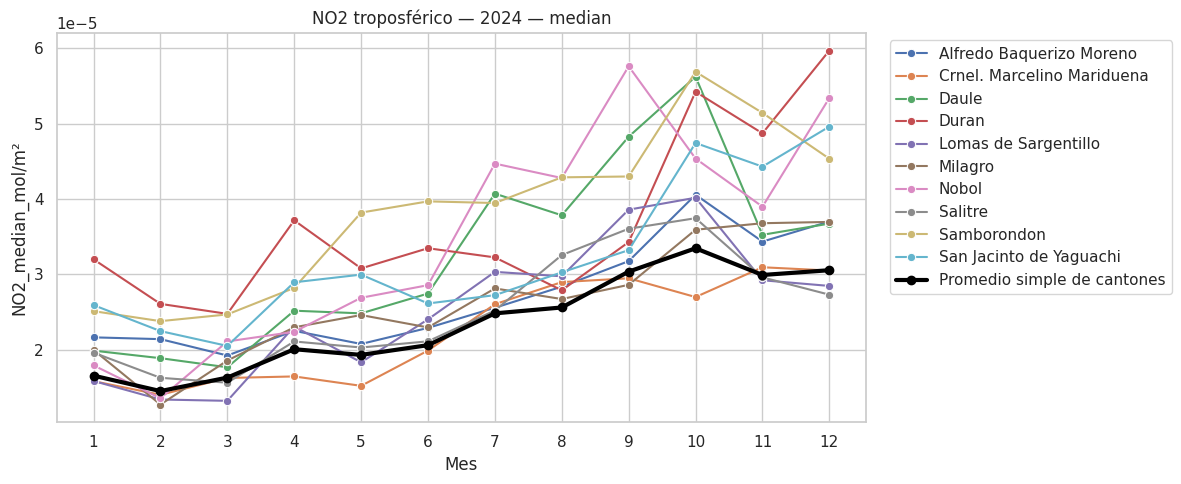

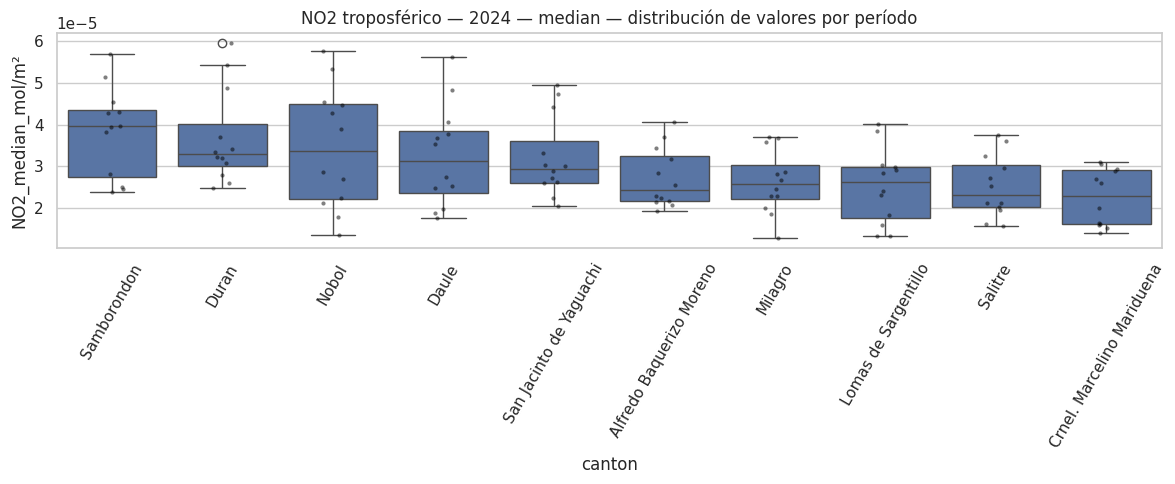

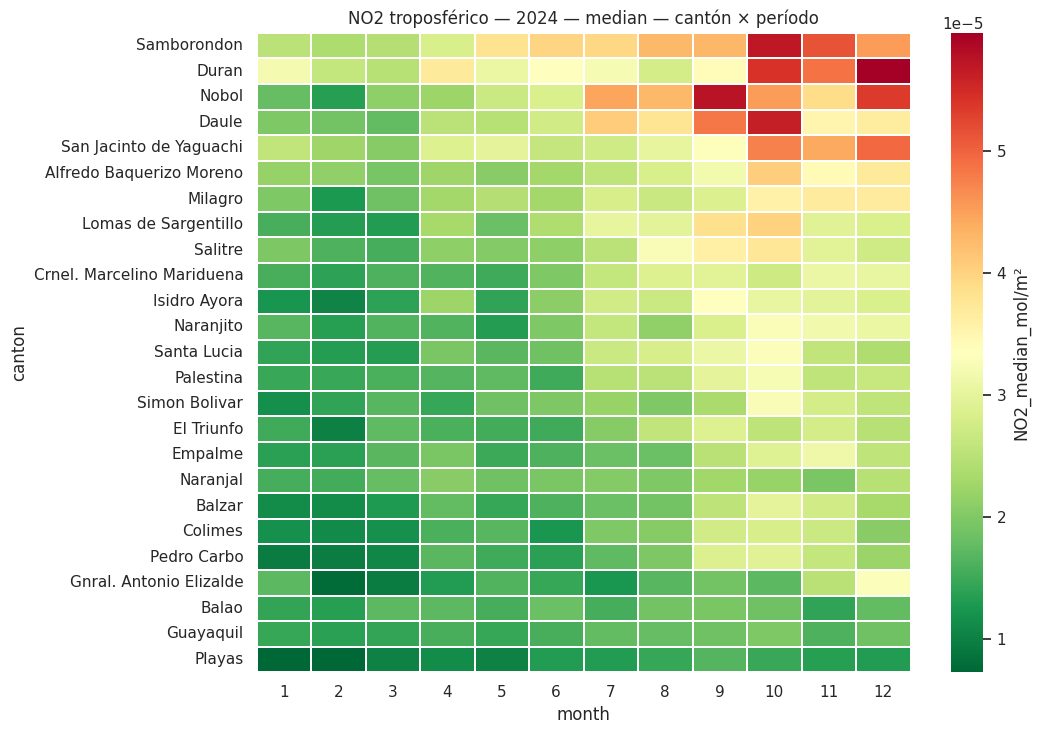

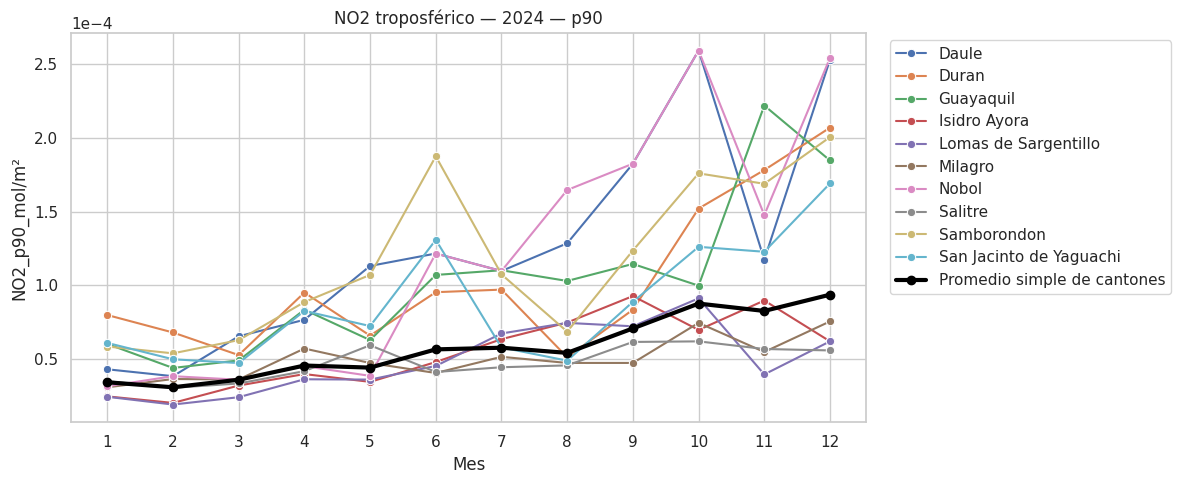

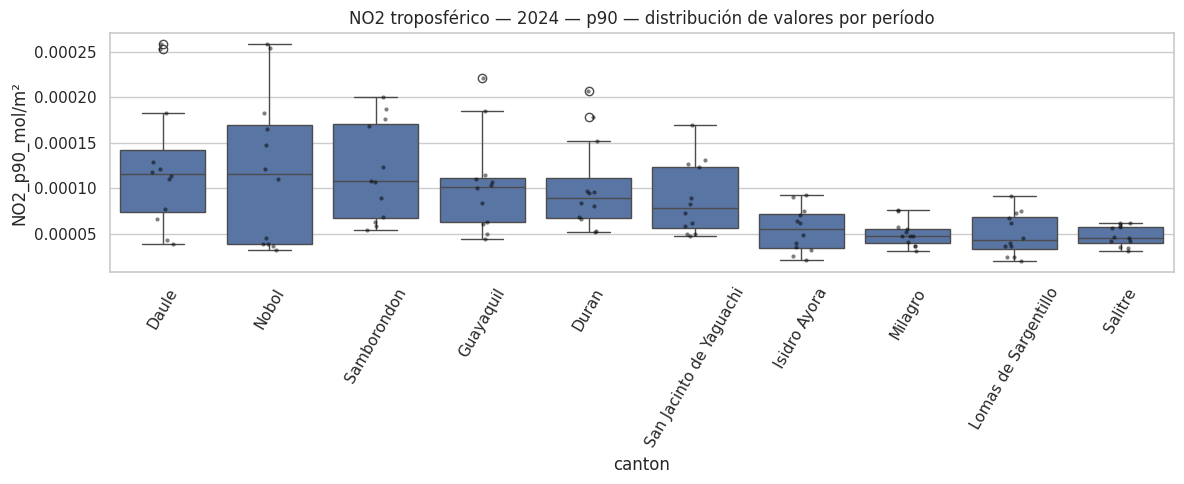

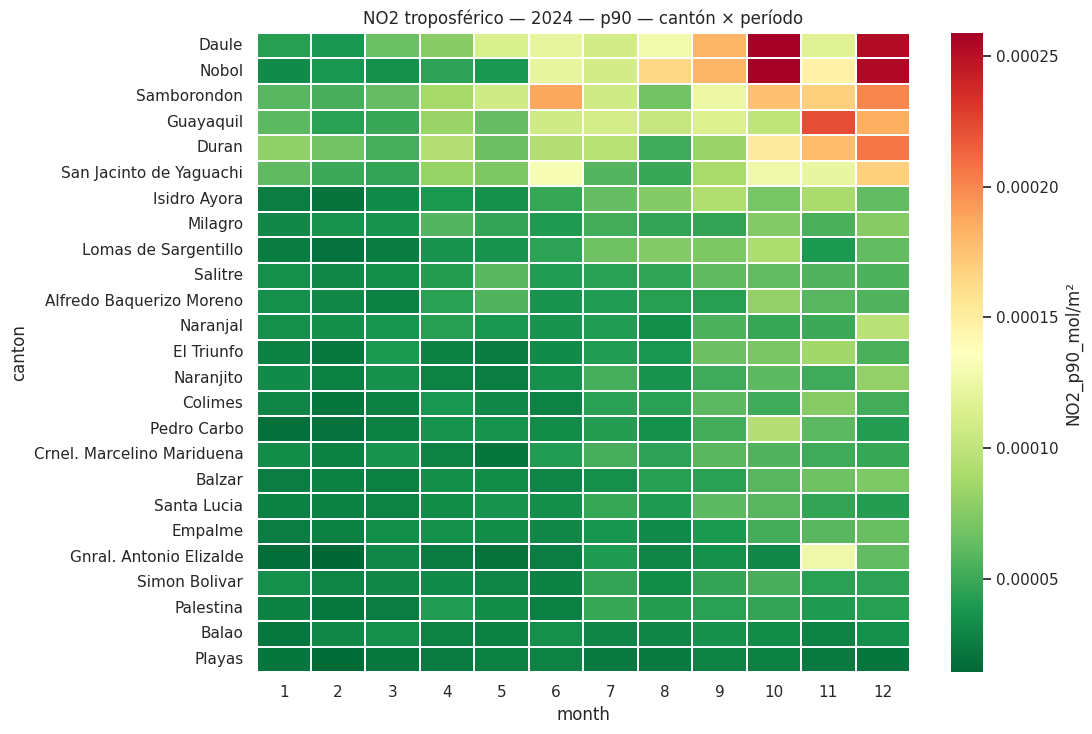

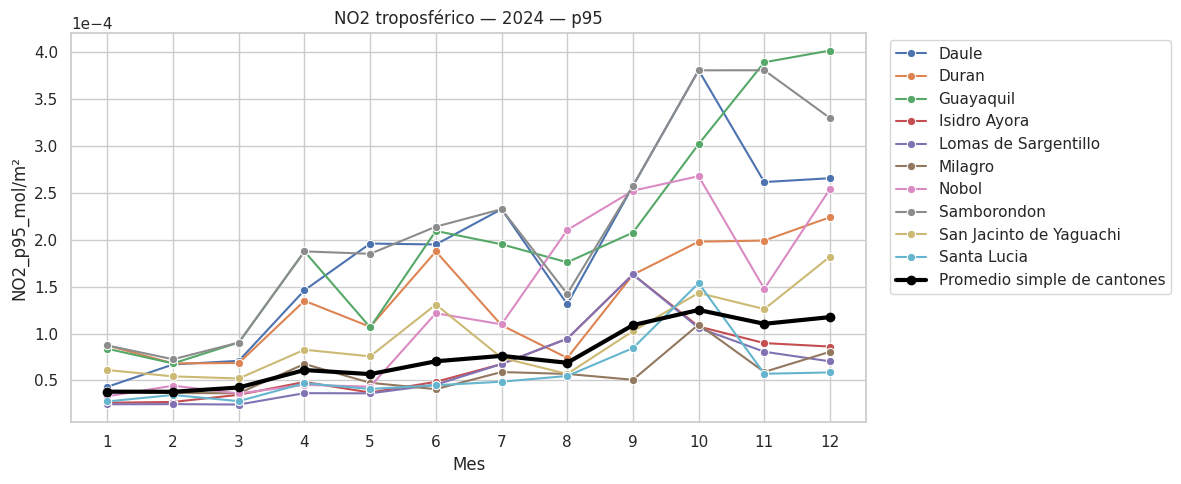

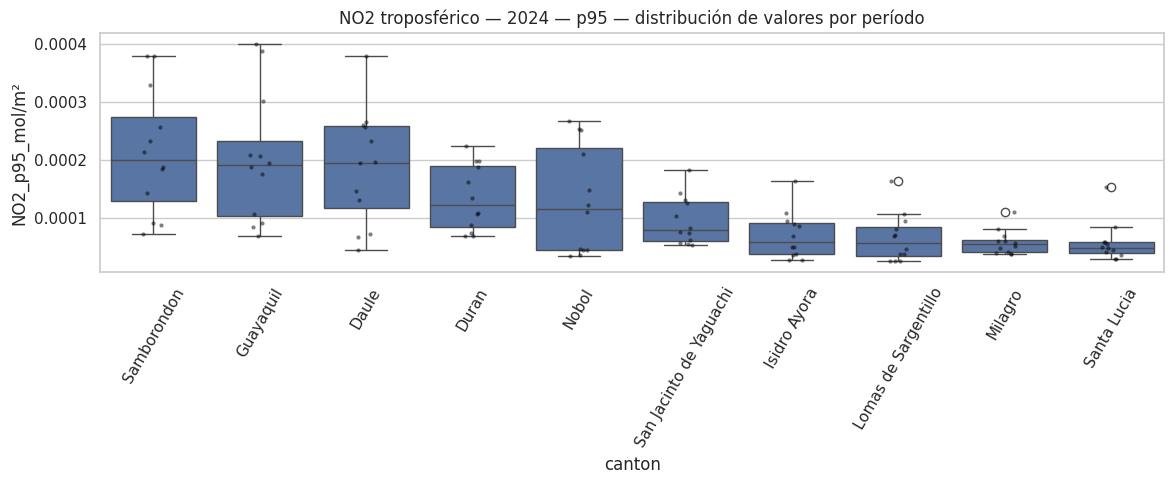

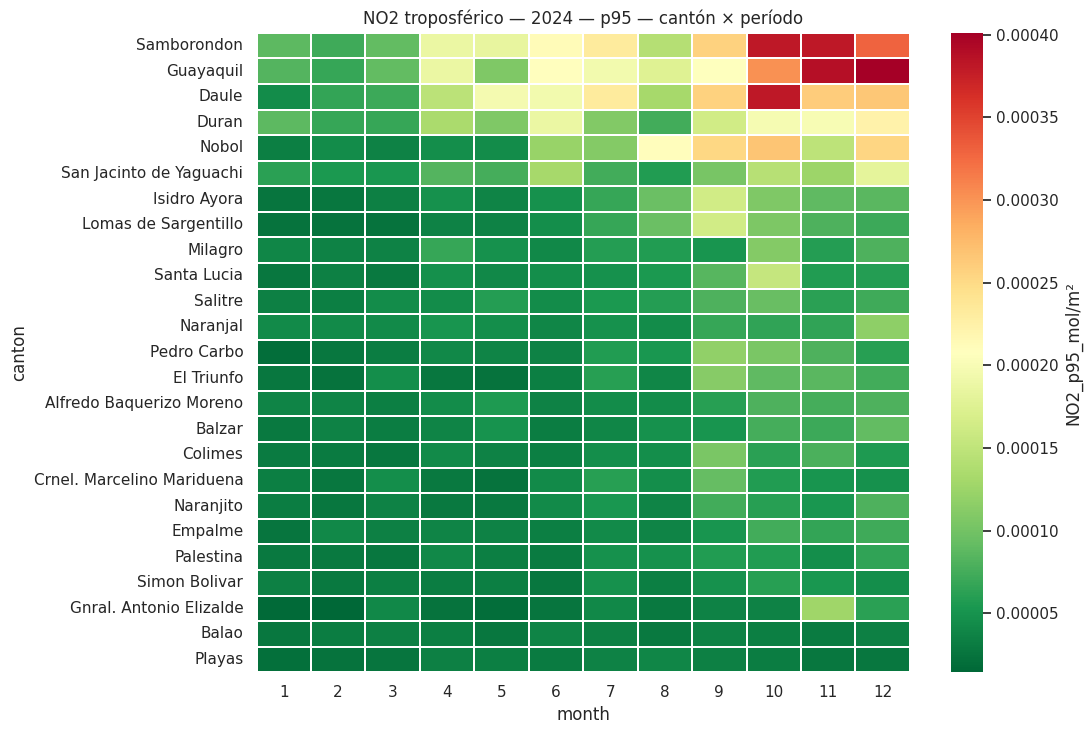

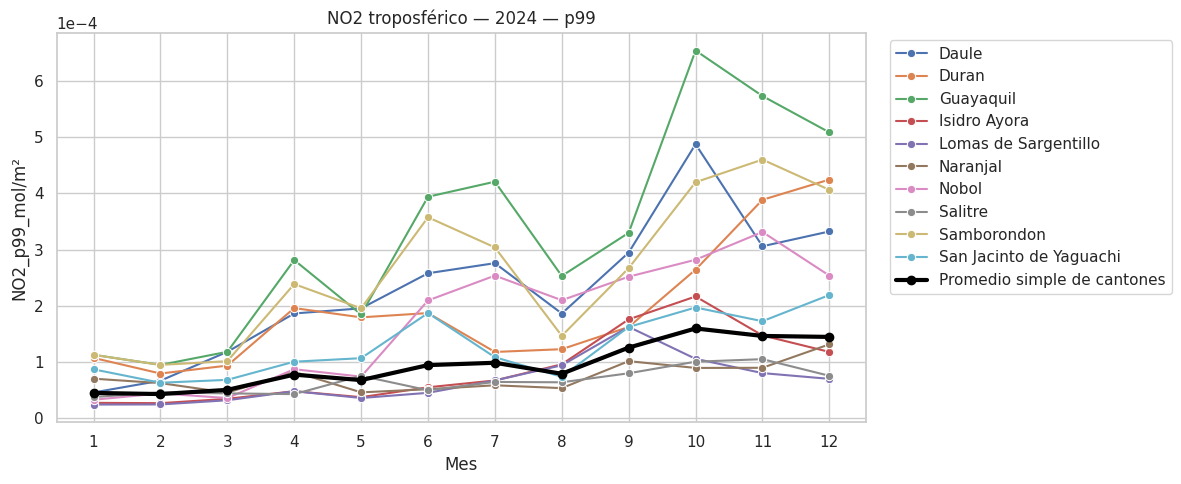

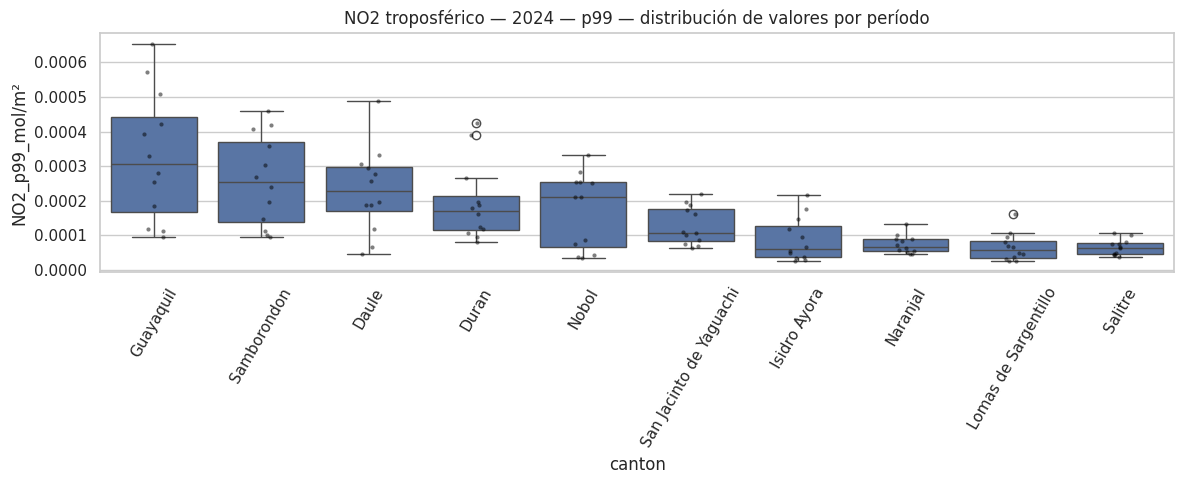

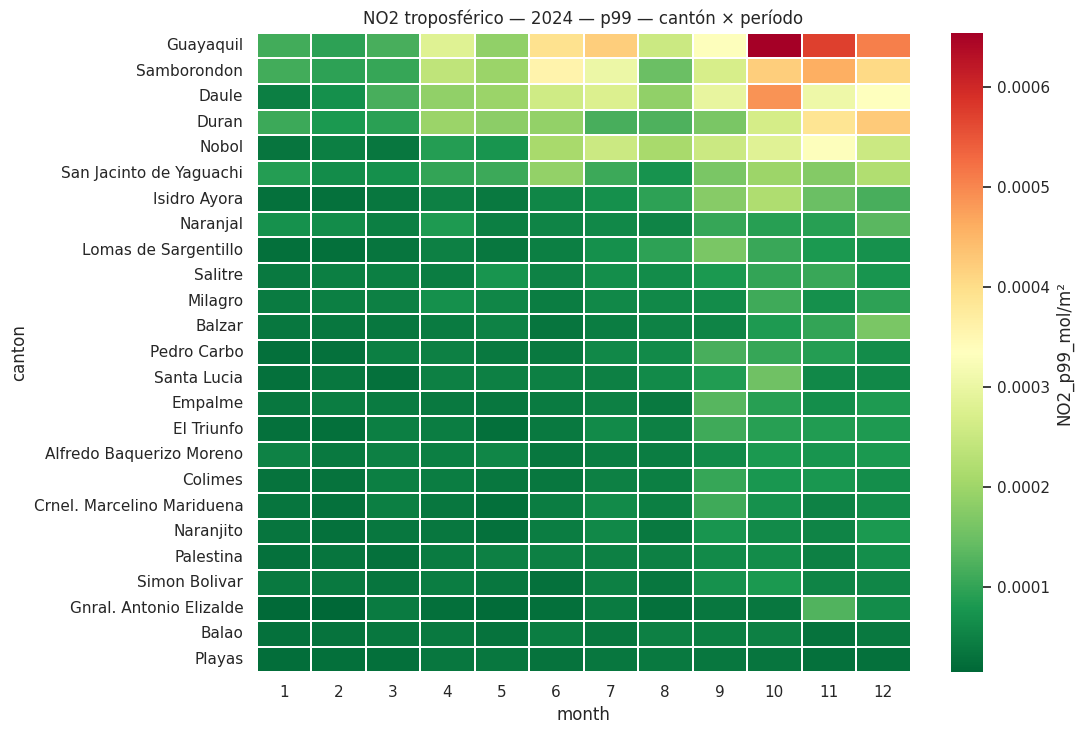

In [11]:
monthly_results = {}

if RUN_MONTHLY:
    for cfg in POLLUTANTS:
        collection = load_collection(
            cfg, YEAR_TO_ANALYZE, YEAR_TO_ANALYZE
        )

        periods = {}
        for month in range(1, 13):
            start = ee.Date.fromYMD(YEAR_TO_ANALYZE, month, 1)
            monthly = collection.filterDate(
                start, start.advance(1, "month")
            )
            periods[month] = (monthly, monthly.size().getInfo())

        for task in STAT_TASKS:
            label = stat_label(task)
            images, rows = {}, []

            for month, (monthly, count) in periods.items():
                image = (
                    stat_image(monthly, task).clip(bounds)
                    if count else None
                )
                if image is not None:
                    images[month] = image

                rows.extend(table_rows(
                    image, task,
                    {
                        "year": YEAR_TO_ANALYZE,
                        "month": month,
                        "month_label": f"{YEAR_TO_ANALYZE}-{month:02d}",
                    },
                    count, count
                ))

            value_col = (
                f'{cfg["POLLUTANT_NAME"]}_{label}_{cfg["POLLUTANT_UNIT"]}'
            )
            df = pd.DataFrame(rows).rename(columns={"value": value_col})
            df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
            df = df.sort_values(["canton", "month"]).reset_index(drop=True)
            df["has_data_month"] = (df["n_images"] > 0).astype(int)

            filename = (
                f'{cfg["POLLUTANT_NAME"].lower()}_cantones_guayas_'
                f'monthly_{YEAR_TO_ANALYZE}_{label}.csv'
            )
            df.to_csv(output_dir / filename, index=False)

            result = {
                "cfg": cfg,
                "task": task,
                "df": df,
                "value_col": value_col,
                "images": images,
            }
            monthly_results[(cfg["POLLUTANT_NAME"], label)] = result

            plot_results(
                result, "month",
                f'{cfg["POLLUTANT_NAME"]} troposférico — '
                f'{YEAR_TO_ANALYZE} — {label}'
            )

**12.Exportación de mapas mensuales**

Objetivo: comparar los meses con una escala fija dentro del año.

Se conserva el criterio mensual original: mínimo y máximo del compuesto del año completo. Esta escala mensual no es necesariamente la misma que la escala de comparación interanual.

In [12]:
if RUN_MONTHLY and DOWNLOAD_MAPS:
    for (pollutant, label), result in monthly_results.items():
        if not result["images"]:
            continue

        annual_collection = load_collection(
            result["cfg"], YEAR_TO_ANALYZE, YEAR_TO_ANALYZE
        )
        reference = image_for_map(
            stat_image(annual_collection, result["task"]),
            result["task"]
        )
        low, high = common_limits({YEAR_TO_ANALYZE: reference},
                                  percentiles=False)

        save_legend(
            result, low, high,
            f"{pollutant.lower()}_{label}_leyenda_mensual_"
            f"{YEAR_TO_ANALYZE}.png"
        )

        for month, image in result["images"].items():
            png = render_png(
                image_for_map(image, result["task"]), low, high
            )
            filename = (
                f"{pollutant.lower()}_{label}_{DOWNLOAD_MODE}_"
                f"{YEAR_TO_ANALYZE}_{month:02d}.png"
            )
            (output_dir / filename).write_bytes(png)

        print("Mapas mensuales guardados:", pollutant, label)

Mapas mensuales guardados: NO2 median
Mapas mensuales guardados: NO2 p90
Mapas mensuales guardados: NO2 p95
Mapas mensuales guardados: NO2 p99


**DESCARGAR LOS ARCHIVO GENERADOS**

In [17]:
import shutil
from pathlib import Path

carpeta = Path("resultados_sentinel5p")   # ajusta la ruta si es distinta
zip_base = "resultados_sentinel5p"

if not carpeta.exists():
    raise FileNotFoundError(f"No existe la carpeta: {carpeta.resolve()}")

# Crea resultados_sentinel5p.zip con todo el contenido (incluye subcarpetas)
zip_path = shutil.make_archive(zip_base, "zip", root_dir=carpeta)
print("ZIP creado:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(zip_path))

ZIP creado: /content/resultados_sentinel5p.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>